In [64]:
import os
from dotenv import load_dotenv
load_dotenv()

GROQ_API_KEY=os.getenv('GROQ_API_KEY')

In [ ]:
from typing import TypedDict , List

from langgraph.graph import StateGraph 

from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage , AIMessage

In [71]:
class AgentState(TypedDict):
    message : List[HumanMessage]
    
    
model = ChatGroq(model="openai/gpt-oss-120b")


In [72]:
def process(state : AgentState) -> AgentState:
    response = model.invoke(state['message'])
    print(response.content)
    return state

In [73]:
graph = StateGraph(AgentState)
graph.add_node('process', process)

graph.set_entry_point('process')
graph.set_finish_point('process')

agent = graph.compile()


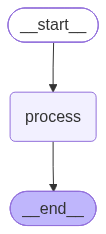

In [74]:
agent

In [75]:
agent.invoke({
    'message':[HumanMessage(content='Hi i am dev .')]
})

Hello! Nice to meet you. How can I help you today?


{'message': [HumanMessage(content='Hi i am dev .', additional_kwargs={}, response_metadata={})]}